# 03 — Edge-IIoTset Data Preparation

**Goal:** Prepare train/validation/test datasets without removing any records.

**Input:** Core16 dataset from Notebook 02.

**Output:** Frozen manifest, three CSV.GZ files, three Excel copies, one report and one graph.

**Rule:** Identical normalized feature patterns stay together. The held-out test set is not scored.

In [1]:
from pathlib import Path
import hashlib, json, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path(r'D:\J26-CS-336-Network-Flow-V2\network_flow_v2')
SELECTED = ROOT / 'data/processed/edge_iiotset/edge_iiotset_core16_selected_v3.csv.gz'
AUDIT1 = ROOT / 'reports/audits/edge_iiotset_v3_dataset_analysis.json'
AUDIT2 = ROOT / 'reports/audits/edge_iiotset_v3_feature_quality.json'
SPLITS = ROOT / 'data/splits/edge_iiotset'
MANIFEST = SPLITS / 'edge_iiotset_core16_signature_split_manifest_v3.csv'
REPORT = ROOT / 'reports/audits/edge_iiotset_v3_split_report.json'
FIGURE = ROOT / 'reports/figures/edge_iiotset_v3_split_class_balance.png'
EXCEL_SCRIPT = ROOT / 'scripts/export_edge_iiotset_splits_excel.ps1'
PARTS = ('train', 'validation', 'test')
FRACTIONS = np.array([0.70, 0.15, 0.15])
EXPECTED_ROWS = 157800
SEED = 42
EXPORT_EXCEL = True  # Requires Microsoft Excel desktop on Windows.
MISSING = {'', '-', '?', 'na', 'n/a', 'nan', 'none', 'null', 'missing', 'unknown'}

for path in (SELECTED, AUDIT1, AUDIT2):
    if not path.is_file():
        raise FileNotFoundError(f'Missing Notebook 01/02 input: {path}')
a1 = json.loads(AUDIT1.read_text(encoding='utf-8'))
a2 = json.loads(AUDIT2.read_text(encoding='utf-8'))
FEATURES = a2['selected_features']
CATEGORICAL = a2['categorical_features']
NUMERIC = a2['numeric_features']
FIELDS = ['csv_row_index_0based'] + FEATURES + ['Attack_label', 'Attack_type']
if (len(FEATURES) != 16 or len(CATEGORICAL) != 2 or len(NUMERIC) != 14 or
    set(CATEGORICAL + NUMERIC) != set(FEATURES)):
    raise ValueError('Core16 feature types do not match Notebook 02.')
if (a1.get('rows') != EXPECTED_ROWS or a2.get('rows') != EXPECTED_ROWS or
    a2.get('export_columns') != FIELDS or
    a2.get('source_sha256_from_notebook_01') != a1.get('source_sha256')):
    raise ValueError('Notebook 01/02 audit metadata differs. Do not split.')
for folder in (SPLITS, REPORT.parent, FIGURE.parent):
    folder.mkdir(parents=True, exist_ok=True)
print(f'Edge-IIoTset: {EXPECTED_ROWS:,} rows | {len(FEATURES)} features')
print('Data are packet/protocol records, not verified connection flows.')

Edge-IIoTset: 157,800 rows | 16 features
Data are packet/protocol records, not verified connection flows.


## 1. Verify selected data

Check all original row IDs, labels, and 19 columns.

In [2]:
frame = pd.read_csv(SELECTED, dtype=str, keep_default_na=False, low_memory=False)
if frame.columns.tolist() != FIELDS or len(frame) != EXPECTED_ROWS:
    raise ValueError(f'Core16 export schema/count mismatch: {len(frame):,} rows.')
ids = pd.to_numeric(frame['csv_row_index_0based'], errors='raise').to_numpy(dtype=np.int64)
if not np.array_equal(ids, np.arange(EXPECTED_ROWS, dtype=np.int64)):
    raise ValueError('Original row IDs changed. No reordering/removal allowed.')
if not set(frame['Attack_label'].unique()) == {'0', '1'}:
    raise ValueError('Expected 0=Normal / 1=Attack.')
normal_type = frame['Attack_type'].str.strip().str.casefold().eq('normal')
if (normal_type != frame['Attack_label'].eq('0')).any():
    raise ValueError('Attack_label and Attack_type do not agree.')
count = frame['Attack_label'].value_counts()
if int(count['0']) != 24301 or int(count['1']) != 133499:
    raise ValueError('Unexpected Normal/Attack balance.')
print(f'All {len(frame):,} rows verified | 19 columns | labels separate from features')
display(pd.DataFrame({'class': ['Normal', 'Attack'], 'rows':[int(count['0']),int(count['1'])]}))

All 157,800 rows verified | 19 columns | labels separate from features


,class,rows
0,Normal,24301
1,Attack,133499


## 2. Find identical Core16 feature groups

Use the same normalization as Notebook 02. Numeric zero is not missing. Labels never enter the feature groups.

In [3]:
canonical = pd.DataFrame(index=frame.index)
for col in FEATURES:
    values = frame[col].astype(str).str.strip()
    absent = values.str.casefold().isin(MISSING)
    if col in NUMERIC:
        parsed = pd.to_numeric(values.mask(absent), errors='coerce')
        parsed = parsed.replace([np.inf, -np.inf], np.nan)
        canonical[col] = parsed.astype('string').fillna('__MISSING__')
    else:
        canonical[col] = values.mask(absent, '__MISSING__')

# Exact grouping (not only hash-based). Keep mixed-label groups intact.
group_ids = canonical.groupby(FEATURES, sort=False, dropna=False).ngroup().to_numpy(dtype=np.int64)
fingerprints = pd.util.hash_pandas_object(canonical, index=False).to_numpy(dtype=np.uint64)
source = pd.DataFrame({'group': group_ids, 'attack':frame['Attack_label'].eq('1').to_numpy(dtype=np.int8)})
groups = source.groupby('group', sort=True).agg(rows=('attack','size'),attacks=('attack','sum'))
groups['normal'] = groups['rows'] - groups['attacks']
if len(np.unique(fingerprints)) != len(groups):
    raise ValueError('A feature-hash collision was detected. Investigate before freezing.')
pattern_report = a2['pattern_diagnostics']
expected_groups = pattern_report['distinct_normalized_feature_patterns']
conflicting = groups[(groups.attacks > 0) & (groups.normal > 0)]
if (len(groups) != expected_groups or len(conflicting) != pattern_report['conflicting_binary_label_groups'] or
    int(conflicting.rows.sum()) != pattern_report['rows_in_conflicting_groups']):
    raise ValueError('Feature grouping differs from Notebook 02. Stop before splitting.')
print(f'Unique Core16 groups: {len(groups):,} | Mixed-label groups: {len(conflicting):,}')
print(f'Rows in mixed-label groups: {int(conflicting.rows.sum()):,}')
print('A repeated pattern with conflicting labels must remain in ONE partition.')

Unique Core16 groups: 110,175 | Mixed-label groups: 1
Rows in mixed-label groups: 4,215
A repeated pattern with conflicting labels must remain in ONE partition.


## 3. Create or reuse frozen split

Assign complete feature groups to approximately 70% training, 15% validation and 15% testing. The split is class-aware, not session-independent.

In [4]:
manifest_columns = ['csv_row_index_0based', 'partition', 'Attack_label', 'core16_signature_hex']
signature_hex = np.array([f'{int(x):016x}' for x in fingerprints])
if MANIFEST.is_file():
    frozen = pd.read_csv(MANIFEST, dtype=str, keep_default_na=False)
    if frozen.columns.tolist() != manifest_columns or len(frozen) != EXPECTED_ROWS:
        raise ValueError('Frozen manifest schema/count mismatch. Do not recreate it.')
    if not (np.array_equal(frozen['csv_row_index_0based'].astype('int64').to_numpy(), ids) and
            np.array_equal(frozen['Attack_label'].to_numpy(), frame['Attack_label'].to_numpy()) and
            np.array_equal(frozen['core16_signature_hex'].to_numpy(), signature_hex)):
        raise ValueError('Current Core16 data differs from frozen manifest. Stop.')
    partitions = frozen['partition'].to_numpy()
    if set(np.unique(partitions)) != set(PARTS):
        raise ValueError('Unexpected partition names in frozen manifest.')
    print('Reused frozen manifest:', MANIFEST.name)
else:
    if any(SPLITS.glob('edge_iiotset_core16_*_v3.csv.gz')) or any(SPLITS.glob('edge_iiotset_core16_*_v3.xlsx')):
        raise FileExistsError('Existing split/Excel files found without a manifest. Inspect first.')
    sizes = groups['rows'].to_numpy(dtype=np.int64)
    normal = groups['normal'].to_numpy(dtype=np.int64)
    attacks = groups['attacks'].to_numpy(dtype=np.int64)
    class_totals = np.array([int(normal.sum()), int(attacks.sum())], dtype=float)
    quotas = FRACTIONS[:, None] * class_totals[None, :]
    current = np.zeros((len(PARTS), 2), dtype=float)
    rng = np.random.default_rng(SEED)
    # Large groups first; ties randomly ordered using frozen seed.
    order = np.lexsort((rng.random(len(sizes)), -sizes))
    assignments = np.empty(len(sizes), dtype=np.uint8)
    scale = np.maximum(class_totals, 1.0) ** 2
    for group_index in order:
        values = np.array([normal[group_index], attacks[group_index]], dtype=float)
        gains = ((2 * (quotas - current) * values - values * values) / scale).sum(axis=1)
        chosen = int(np.argmax(gains))
        assignments[group_index] = chosen
        current[chosen] += values
    group_assignment = pd.Series(assignments, index=groups.index)
    chosen_per_row = pd.Series(group_ids).map(group_assignment)
    if chosen_per_row.isna().any():
        raise ValueError('Some feature groups were not assigned.')
    partitions = np.array(PARTS)[chosen_per_row.to_numpy(dtype=np.int64)]
    preview = pd.DataFrame({'group':group_ids,'partition':partitions})
    overlap = int((preview.groupby('group')['partition'].nunique() > 1).sum())
    ratios = np.array([(partitions == part).mean() for part in PARTS])
    if overlap or np.any(abs(ratios - FRACTIONS) > 0.03):
        raise ValueError(f'Unsafe proposed split: overlapping groups={overlap}; fractions={ratios}')
    tmp = Path(str(MANIFEST) + '.tmp')
    if tmp.exists():
        raise FileExistsError(f'Partial manifest exists: {tmp}')
    new_manifest = pd.DataFrame({
        'csv_row_index_0based': ids,
        'partition': partitions,
        'Attack_label': frame['Attack_label'].to_numpy(),
        'core16_signature_hex': signature_hex
    })
    new_manifest.to_csv(tmp, index=False)
    tmp.replace(MANIFEST)
    print('Created new frozen manifest:', MANIFEST.name)

membership = pd.DataFrame({'group': group_ids, 'partition':partitions})
overlap_groups = int((membership.groupby('group')['partition'].nunique() > 1).sum())
if overlap_groups:
    raise ValueError(f'{overlap_groups} groups cross partitions. Stop.')
counts = []
for p in PARTS:
    labels = frame.loc[partitions == p, 'Attack_label']
    counts.append({'partition':p,'Normal':int(labels.eq('0').sum()),
                   'Attack':int(labels.eq('1').sum()),'Total':int(len(labels))})
summary = pd.DataFrame(counts).set_index('partition')
ratios = summary['Total'].to_numpy() / EXPECTED_ROWS
if (int(summary.Total.sum()) != EXPECTED_ROWS or
    not ((summary['Normal'] > 0) & (summary['Attack'] > 0)).all() or
    np.any(abs(ratios - FRACTIONS) > 0.03)):
    raise ValueError('Frozen split is invalid or too far from 70/15/15.')
print(f'All rows preserved: {int(summary.Total.sum()):,}/{EXPECTED_ROWS:,} (100%)')
print('Overlapping normalized Core16 feature groups:', overlap_groups)
display(summary)
# Attack-type distribution: class-aware split does NOT guarantee every type in every partition.
attack_type = pd.crosstab(pd.Series(partitions,name='partition'), frame['Attack_type'])
missing_types = [col for col in attack_type if (attack_type[col] == 0).any()]
if missing_types:
    print('Warning: attack types absent from at least one partition:', missing_types)
display(attack_type)

Created new frozen manifest: edge_iiotset_core16_signature_split_manifest_v3.csv
All rows preserved: 157,800/157,800 (100%)
Overlapping normalized Core16 feature groups: 0


,Normal,Attack,Total
partition,,,
train,17011,93449,110460
validation,3645,20025,23670
test,3645,20025,23670


Attack_type,Backdoor,DDoS_HTTP,DDoS_ICMP,DDoS_TCP,DDoS_UDP,Fingerprinting,MITM,Normal,Password,Port_Scanning,Ransomware,SQL_injection,Uploading,Vulnerability_scanner,XSS
partition,,,,,,,,,,,,,,,
test,191,1645,2784,2357,3002,70,2,3645,1812,2214,307,1884,1557,1164,1036
train,9822,7253,8392,5583,8500,866,1212,17011,6267,5667,10340,6528,7171,7776,8072
validation,182,1663,2914,2307,2996,65,0,3645,1910,2190,278,1899,1541,1136,944


## 4. Export and verify CSV.GZ files

Every row and label is kept. Existing frozen exports are verified, never silently overwritten.

In [5]:
OUTPUTS = {part: SPLITS / f'edge_iiotset_core16_{part}_v3.csv.gz' for part in PARTS}
file_details = {}
for part in PARTS:
    target = OUTPUTS[part]
    expected = frame.loc[partitions == part, FIELDS].reset_index(drop=True)
    temp = Path(str(target) + '.tmp')
    if temp.exists():
        raise FileExistsError(f'Partial CSV found: {temp}')
    if not target.is_file():
        expected.to_csv(temp, index=False, compression='gzip')
        candidate = pd.read_csv(temp, dtype=str, keep_default_na=False, compression='gzip')
        if candidate.columns.tolist() != FIELDS or not candidate.equals(expected):
            temp.unlink(missing_ok=True)
            raise ValueError(f'CSV verification failed for {part}.')
        del candidate
        temp.replace(target)
        print('Created:', target.name)
    else:
        print('Reused:', target.name)
    check = pd.read_csv(target, dtype=str, keep_default_na=False)
    if check.columns.tolist() != FIELDS or not check.equals(expected):
        raise ValueError(f'Saved {part} CSV differs from frozen assignment; do not overwrite.')
    file_details[part] = {'name':target.name,'rows':len(check),'bytes':target.stat().st_size}
    del check, expected
if sum(item['rows'] for item in file_details.values()) != EXPECTED_ROWS:
    raise ValueError('Split export lost records.')
print('All three complete CSV.GZ datasets verified. The test set is not scored.')

Created: edge_iiotset_core16_train_v3.csv.gz
Created: edge_iiotset_core16_validation_v3.csv.gz
Created: edge_iiotset_core16_test_v3.csv.gz
All three complete CSV.GZ datasets verified. The test set is not scored.


## 5. Save report and split graph

Report all class counts and the limitations of the split.

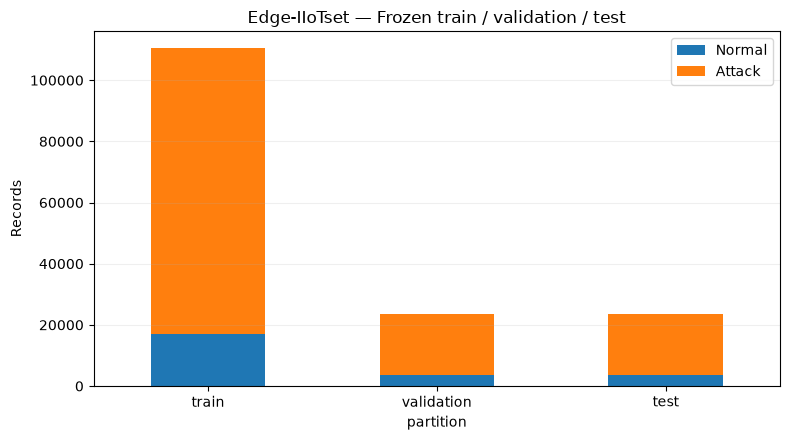

Saved: D:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\audits\edge_iiotset_v3_split_report.json
Saved: D:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\figures\edge_iiotset_v3_split_class_balance.png


In [6]:
fig, ax = plt.subplots(figsize=(8,4.5))
summary[['Normal','Attack']].plot(kind='bar', stacked=True, ax=ax, rot=0)
ax.set_title('Edge-IIoTset — Frozen train / validation / test')
ax.set_ylabel('Records')
ax.grid(axis='y', alpha=.2)
fig.tight_layout()
fig.savefig(FIGURE, dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)

sha = hashlib.sha256(MANIFEST.read_bytes()).hexdigest()
report = {
    'dataset':'Edge-IIoTset',
    'source_rows':EXPECTED_ROWS,
    'selected_features':FEATURES,
    'categorical_features':CATEGORICAL,
    'target':'Attack_label',
    'attack_type':'Attack_type',
    'manifest_name':MANIFEST.name,
    'manifest_sha256':sha,
    'seed_for_first_split':SEED,
    'method':'class-aware assignment of complete, exactly normalized Core16 feature groups',
    'fractions_requested':dict(zip(PARTS, FRACTIONS.tolist())),
    'counts':{part:{'rows':int(summary.at[part,'Total']),
                    'normal':int(summary.at[part,'Normal']),
                    'attack':int(summary.at[part,'Attack'])} for part in PARTS},
    'total_rows_preserved':EXPECTED_ROWS,
    'normalized_feature_group_overlap':overlap_groups,
    'conflicting_label_groups':len(conflicting),
    'rows_in_conflicting_label_groups':int(conflicting.rows.sum()),
    'exported_columns':FIELDS,
    'num_columns':len(FIELDS),
    'files':file_details,
    'test_scored':False,
    'limitations':[
        'Exact Core16 group isolation does not establish independent devices, capture sessions or attacks.',
        'One mixed-label group contains 4,215 indistinguishable feature records; no rows removed.',
        'Packet/protocol data are not verified as network flow features.',
        'The labels are class-imbalanced and several protocol fields are zero-heavy.',
        'No held-out test predictions have been generated.'
    ]
}
REPORT.write_text(json.dumps(report, indent=2), encoding='utf-8')
print('Saved:', REPORT)
print('Saved:', FIGURE)

## 6. Export Excel files beside CSV.GZ

Make readable Excel copies of all three partitions in the **same** split folder. Excel is not used for training.

In [7]:
if EXPORT_EXCEL:
    if not EXCEL_SCRIPT.is_file():
        raise FileNotFoundError(f'Missing Excel export script: {EXCEL_SCRIPT}')
    subprocess.run(['powershell.exe','-NoProfile','-ExecutionPolicy','Bypass',
                    '-File',str(EXCEL_SCRIPT),'-ProjectRoot',str(ROOT)], check=True)
    for part in PARTS:
        excel = SPLITS / f'edge_iiotset_core16_{part}_v3.xlsx'
        if not excel.is_file() or excel.stat().st_size == 0:
            raise ValueError(f'Excel copy missing/empty: {excel}')
    print('Three Excel copies saved beside their CSV.GZ files.')
else:
    print('Excel export disabled. To enable, set EXPORT_EXCEL=True.')
print('Next: Edge-IIoTset Notebook 04 — five separate model-training experiments.')

Three Excel copies saved beside their CSV.GZ files.
Next: Edge-IIoTset Notebook 04 — five separate model-training experiments.
